# Лабораторная работа №5. Градиентный бустинг

**Цель:** провести исследование градиентного бустинга над решающими деревьями на задачах классификации (Dota 2) и регрессии (шахматный эндшпиль KRKPA7): бейзлайн `sklearn`, улучшение через проверку гипотез, собственная реализация и сравнение (пункты 2–4 ЛР №1).

Наборы данных, постановка задач и обоснование метрик — в разделе 1 ЛР №1 (`lab1_knn.ipynb`). Метрики: классификация — **ROC-AUC** (основная), accuracy, F1; регрессия — **R²** (основная), RMSE, MAE.

Итоговое сравнение всех алгоритмов из ЛР №1–5 вынесено в отдельный ноутбук `summary.ipynb`.

## 0. Подготовка окружения

Импортируем библиотеки и общий пакет `mllab` из корня репозитория. В `mllab` лежат:
загрузчики данных (`mllab.data`), генераторы признаков (`mllab.features`), функции подсчёта метрик и журнал результатов (`mllab.metrics`), а также собственные реализации алгоритмов (`mllab.knn`, `mllab.linear`, `mllab.tree`, `mllab.forest`, `mllab.boosting`).
Предупреждения отключаем, чтобы не засорять вывод; для `Pipeline` включаем дисковый кэш (`.cache/`), чтобы тяжёлые преобразования признаков не пересчитывались в каждом прогоне кросс-валидации.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import inspect

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Code, display
from joblib import Memory
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler

import mllab
from mllab.data import RANDOM_STATE, load_chess, load_dota
from mllab.features import ChessFeatures, DotaFeatures
from mllab.metrics import ResultsLog, compare_cv, cv_report, evaluate

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 120)
memory = Memory(ROOT / ".cache", verbose=0)

Загружаем данные (подробное описание и обоснование выбора — в разделе 1 ЛР №1):
* **классификация** — *Dota 2 Games Results*: используем официальное разбиение UCI на train (92 650 матчей) и test (10 294 матча); целевая переменная `1` — победила команда 1;
* **регрессия** — *Chess KR vs KP (KRKPA7)*: стратифицированное разбиение 80/20 (`random_state=42`); целевая переменная `1.0` — белые выигрывают, `0.0` — нет; модель предсказывает непрерывную «оценку позиции».

Гиперпараметры подбираем только на train через 5-кратную кросс-валидацию (`StratifiedKFold` для классификации, `KFold` для регрессии); test используется только для финальной оценки.

In [2]:
X_cls_train, X_cls_test, y_cls_train, y_cls_test = load_dota()
X_reg_train, X_reg_test, y_reg_train, y_reg_test = load_chess()

cv_cls = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_reg = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("Классификация (Dota 2):", X_cls_train.shape, X_cls_test.shape)
print("Регрессия (шахматы KRKPA7):", X_reg_train.shape, X_reg_test.shape)

log = ResultsLog(lab=5, algorithm="GradientBoosting")

Классификация (Dota 2): (92650, 116) (10294, 116)
Регрессия (шахматы KRKPA7): (2556, 36) (640, 36)


## 2. Создание бейзлайна и оценка качества

Бейзлайн — `GradientBoostingClassifier` (логистическая функция потерь) и `GradientBoostingRegressor` (квадратичная функция потерь) из `sklearn` с параметрами по умолчанию: 100 деревьев глубины 3, `learning_rate=0.1`, без подвыборки.

In [3]:
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.metrics import r2_score, roc_auc_score
from sklearn.model_selection import train_test_split

baseline_cls = GradientBoostingClassifier(random_state=RANDOM_STATE)
baseline_reg = make_pipeline(ChessFeatures(), GradientBoostingRegressor(random_state=RANDOM_STATE))

log.add("classification", "sklearn baseline",
        evaluate(baseline_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "sklearn baseline",
        evaluate(baseline_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification"), log.table("regression"))

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6118,0.5814,0.6559,16.6416,0.0365


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.8697,0.1803,0.1171,0.2487,0.0041


<!-- lab5_baseline -->
**Вывод по бейзлайну.**
* *Классификация:* бустинг из 100 деревьев глубины 3 даёт ROC-AUC = 0.612 и accuracy = 0.581 — лучше одиночного дерева и случайного леса с параметрами по умолчанию, но хуже логистической регрессии (0.634): неглубокие деревья по одному признаку плохо собирают аддитивный сигнал от 113 героев за 100 итераций. F1 = 0.656 — самый высокий среди бейзлайнов, т. к. модель чаще предсказывает победу команды 1.
* *Регрессия:* R² = 0.870 — заметно хуже одиночного дерева (0.9875). 100 деревьев глубины 3 с шагом 0.1 не успевают выучить логические правила эндшпиля, для которых нужны конъюнкции многих условий: модель **недообучена**.

## 3. Улучшение бейзлайна

### 3.1. Гипотезы

**Классификация (Dota 2):**
* **H1. Новые признаки** драфта (win rate, синергия, контрпики) вместо/вместе с индикаторами героев.
* **H2. Темп обучения и число деревьев.** Меньший `learning_rate` с бо́льшим числом деревьев обычно обобщает лучше; на шумных данных слишком много итераций ведёт к переобучению — ищем оптимум по кривым обучения.
* **H3. Глубина деревьев.** Глубина задаёт порядок взаимодействий признаков, которые может выучить ансамбль; на слабом сигнале выгоднее неглубокие деревья.
* **H4. Стохастический бустинг** (`subsample < 1`): каждое дерево учится на случайной подвыборке — дополнительная регуляризация.

**Регрессия (шахматы):**
* **H1. Число деревьев и темп обучения.** 100 деревьев глубины 3 явно недостаточно, чтобы выучить логические правила эндшпиля (R² бейзлайна заметно ниже, чем у одиночного дерева в ЛР №3).
* **H2. Глубина деревьев.** Правила эндшпиля — конъюнкции многих условий; более глубокие деревья выучивают их за меньшее число итераций.
* **H3. Стохастический бустинг** (`subsample`).

### 3.2. Проверка гипотез для классификации

**H1.** Сравниваем бустинг с параметрами по умолчанию на исходных признаках и на признаках драфта.

In [4]:
h1_cls = compare_cv({
    "исходные признаки": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "индикаторы + статистики": make_pipeline(DotaFeatures(meta="drop", drop_constant=True, synergy=True),
                                             GradientBoostingClassifier(random_state=RANDOM_STATE)),
    "только статистики (7 признаков)": make_pipeline(DotaFeatures(meta="drop", heroes="none", synergy=True),
                                                     GradientBoostingClassifier(random_state=RANDOM_STATE)),
}, X_cls_train, y_cls_train, cv_cls, "roc_auc")
h1_cls

,cv_mean,cv_std,train_mean,fit_time
candidate,,,,
исходные признаки,0.6136,0.0042,0.6383,14.4493
индикаторы + статистики,0.6375,0.0040,0.6792,60.2540
только статистики (7 признаков),0.6370,0.0043,0.6754,27.1491


<!-- lab5_h1_cls -->
**H1 подтверждена.** Признаки драфта повышают ROC-AUC на CV с 0.614 до 0.637–0.638. Варианты «индикаторы + статистики» и «только статистики» неразличимы (0.6375 и 0.6370 при разбросе 0.004), но компактный вариант обучается вдвое быстрее (27 с против 60 с) — выбираем его.

**H2.** Строим кривые обучения: выделяем из train валидационную часть (20 %), обучаем бустинг с разным `learning_rate` на 600 итерациях и с помощью `staged_predict_proba` считаем ROC-AUC на валидации после каждых 10 деревьев.

,лучшее число деревьев,макс. ROC-AUC
learning_rate=0.03,50,0.6462
learning_rate=0.1,20,0.6463
learning_rate=0.3,10,0.6463


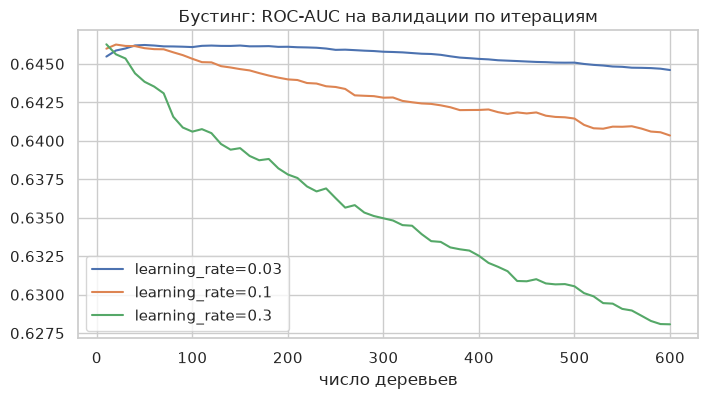

In [5]:
X_sub, X_val, y_sub, y_val = train_test_split(X_cls_train, y_cls_train, test_size=0.2, stratify=y_cls_train,
                                              random_state=RANDOM_STATE)
draft = DotaFeatures(meta="drop", heroes="none", synergy=True)
F_sub, F_val = draft.fit_transform(X_sub, y_sub), draft.transform(X_val)

curves_cls = {}
for lr in [0.03, 0.1, 0.3]:
    staged = GradientBoostingClassifier(n_estimators=600, learning_rate=lr, random_state=RANDOM_STATE).fit(F_sub, y_sub)
    curves_cls[f"learning_rate={lr}"] = pd.Series({
        i + 1: roc_auc_score(y_val, p[:, 1])
        for i, p in enumerate(staged.staged_predict_proba(F_val)) if (i + 1) % 10 == 0
    })
curves_cls = pd.DataFrame(curves_cls)
ax = curves_cls.plot(figsize=(8, 4), title="Бустинг: ROC-AUC на валидации по итерациям")
ax.set_xlabel("число деревьев")
pd.DataFrame({"лучшее число деревьев": curves_cls.idxmax(), "макс. ROC-AUC": curves_cls.max()})

<!-- lab5_h2_cls -->
**H2 подтверждена: на этих данных бустинг быстро начинает переобучаться.** На компактных признаках лучший ROC-AUC на валидации (≈0.646) достигается уже после 10–50 деревьев, после чего качество медленно падает. Чем больше `learning_rate`, тем раньше пик и тем быстрее деградация: при `lr = 0.3` к 600 деревьям ROC-AUC падает до 0.628, при `lr = 0.03` — лишь до 0.645. Малый темп обучения делает модель намного устойчивее к выбору числа итераций.

**H3 и H4.** Совместно подбираем глубину деревьев, темп обучения, число деревьев и долю подвыборки на кросс-валидации.

In [6]:
pipe_cls = Pipeline([
    ("features", DotaFeatures(meta="drop", heroes="none", synergy=True)),
    ("model", GradientBoostingClassifier(random_state=RANDOM_STATE)),
], memory=memory)
search_cls = GridSearchCV(pipe_cls, {
    "model__n_estimators": [200, 400],
    "model__learning_rate": [0.03, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__subsample": [0.8, 1.0],
}, cv=cv_cls, scoring="roc_auc", n_jobs=-1).fit(X_cls_train, y_cls_train)
print("Лучшие параметры:", search_cls.best_params_)
report_cls = cv_report(search_cls, top=24)
report_cls.head(10)

Лучшие параметры: {'model__learning_rate': 0.03, 'model__max_depth': 2, 'model__n_estimators': 200, 'model__subsample': 0.8}


,model__learning_rate,model__max_depth,model__n_estimators,model__subsample,mean_test_score,std_test_score,rank_test_score
0,0.0300,2,200,0.8000,0.6375,0.0041,1
1,0.0300,3,200,0.8000,0.6374,0.0041,2
2,0.0300,2,200,1.0000,0.6374,0.0042,3
3,0.0300,3,200,1.0000,0.6374,0.0043,4
4,0.0300,2,400,0.8000,0.6373,0.0042,5
5,0.0300,2,400,1.0000,0.6373,0.0043,6
6,0.0300,4,200,0.8000,0.6371,0.0043,7
7,0.0300,3,400,0.8000,0.6371,0.0041,8
8,0.0300,4,200,1.0000,0.6370,0.0045,9
9,0.0300,3,400,1.0000,0.6370,0.0044,10


Сравним средний ROC-AUC на кросс-валидации по значениям глубины и доли подвыборки (усреднение по остальным параметрам сетки).

In [7]:
display(report_cls.groupby("model__max_depth")["mean_test_score"].agg(["mean", "max"]),
        report_cls.groupby("model__subsample")["mean_test_score"].agg(["mean", "max"]))

,mean,max
model__max_depth,,
2,0.6369,0.6375
3,0.6363,0.6374
4,0.6350,0.6371


,mean,max
model__subsample,,
0.8000,0.6361,0.6375
1.0000,0.6361,0.6374


<!-- lab5_h34_cls -->
**H3 подтверждена, H4 — не подтверждена.** Лучшая конфигурация — `learning_rate = 0.03`, 200 деревьев **глубины 2**, `subsample = 0.8` (ROC-AUC на CV = 0.6375). В среднем по сетке качество убывает с ростом глубины (0.6369 → 0.6363 → 0.6350 для глубин 2/3/4): сигнал почти аддитивный, и взаимодействия высокого порядка только добавляют шум. Стохастический бустинг на качество не влияет (средние 0.6361 и 0.6361) — разница между лучшими конфигурациями с `subsample` 0.8 и 1.0 в десятитысячных долях.

### 3.3. Проверка гипотез для регрессии

**H1 и H2.** Строим кривые обучения на валидационной части train (20 %) для разной глубины деревьев и темпа обучения (до 1 000 деревьев).

,лучшее число деревьев,макс. R²
"depth=3, lr=0.1",1000,0.9037
"depth=3, lr=0.3",970,0.9125
"depth=5, lr=0.1",540,0.9310
"depth=7, lr=0.1",60,0.9355
"depth=9, lr=0.1",30,0.9382


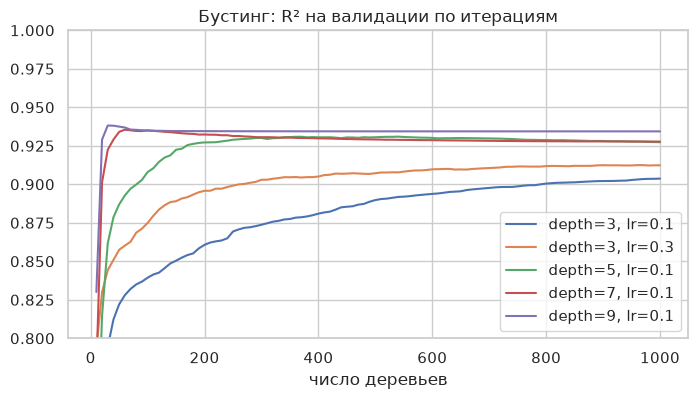

In [8]:
R_sub, R_val, r_sub, r_val = train_test_split(X_reg_train, y_reg_train, test_size=0.2, stratify=y_reg_train,
                                              random_state=RANDOM_STATE)
chess_enc = ChessFeatures().fit(R_sub)
A_sub, A_val = chess_enc.transform(R_sub), chess_enc.transform(R_val)

curves_reg = {}
for depth, lr in [(3, 0.1), (3, 0.3), (5, 0.1), (7, 0.1), (9, 0.1)]:
    staged = GradientBoostingRegressor(n_estimators=1000, max_depth=depth, learning_rate=lr,
                                       random_state=RANDOM_STATE).fit(A_sub, r_sub)
    curves_reg[f"depth={depth}, lr={lr}"] = pd.Series({
        i + 1: r2_score(r_val, p) for i, p in enumerate(staged.staged_predict(A_val)) if (i + 1) % 10 == 0
    })
curves_reg = pd.DataFrame(curves_reg)
ax = curves_reg.plot(figsize=(8, 4), ylim=(0.8, 1.0), title="Бустинг: R² на валидации по итерациям")
ax.set_xlabel("число деревьев")
pd.DataFrame({"лучшее число деревьев": curves_reg.idxmax(), "макс. R²": curves_reg.max()})

<!-- lab5_h12_reg -->
**H1 и H2 подтверждены.** Глубина деревьев — решающий параметр для шахмат: с деревьями глубины 3 даже 1000 итераций дают на валидации R² ≈ 0.90 (кривая ещё растёт), увеличение темпа до 0.3 ускоряет обучение, но не решает проблему. Деревья глубины 7–9 выходят на максимум (≈0.94) уже за 30–60 итераций: одно глубокое дерево выражает целое логическое правило, которое неглубоким деревьям приходится собирать из многих частей. После максимума качество почти не меняется — переобучения на детерминированных данных практически нет.

**H3** и финальный подбор: сетка по числу деревьев, глубине и доле подвыборки на 5-кратной кросс-валидации.

In [9]:
pipe_reg = Pipeline([("features", ChessFeatures()), ("model", GradientBoostingRegressor(random_state=RANDOM_STATE))])
search_reg = GridSearchCV(pipe_reg, {
    "model__n_estimators": [300, 600, 1000],
    "model__max_depth": [5, 7, 9],
    "model__learning_rate": [0.1],
    "model__subsample": [0.8, 1.0],
}, cv=cv_reg, scoring="r2", n_jobs=-1).fit(X_reg_train, y_reg_train)
print("Лучшие параметры:", search_reg.best_params_)
report_reg = cv_report(search_reg, top=18)
display(report_reg.head(10))
report_reg.groupby("model__subsample")["mean_test_score"].agg(["mean", "max"])

Лучшие параметры: {'model__learning_rate': 0.1, 'model__max_depth': 9, 'model__n_estimators': 300, 'model__subsample': 1.0}


,model__learning_rate,model__max_depth,model__n_estimators,model__subsample,mean_test_score,std_test_score,rank_test_score
0,0.1000,9,300,1.0000,0.9806,0.0086,1
1,0.1000,9,600,1.0000,0.9802,0.0088,2
2,0.1000,9,1000,1.0000,0.9801,0.0087,3
3,0.1000,9,300,0.8000,0.9792,0.0073,4
4,0.1000,9,600,0.8000,0.9792,0.0073,5
5,0.1000,9,1000,0.8000,0.9792,0.0073,6
6,0.1000,7,600,1.0000,0.9743,0.0076,7
7,0.1000,7,300,1.0000,0.9740,0.0084,8
8,0.1000,7,1000,1.0000,0.9736,0.0070,9
9,0.1000,7,300,0.8000,0.9733,0.0093,10


,mean,max
model__subsample,,
0.8000,0.9704,0.9792
1.0000,0.9701,0.9806


<!-- lab5_h3_reg -->
**H3 не подтверждена.** По сетке лучшая конфигурация — 300 деревьев глубины 9 без подвыборки (R² на CV = 0.9806); подвыборка 0.8 немного хуже (0.979). Глубина 9 — граница сетки, но разница между 7 и 9 уже невелика (0.974 → 0.981), а отдельное дерево в ЛР №3 имеет глубину 13, так что дальнейшее увеличение приближает бустинг к одиночному дереву. Число деревьев от 300 до 1000 почти не влияет, что согласуется с кривыми обучения.

### 3.4. Улучшенный бейзлайн

* **классификация** — компактные признаки драфта → `GradientBoostingClassifier` с подобранными числом деревьев, темпом обучения, глубиной и подвыборкой;
* **регрессия** — `GradientBoostingRegressor` с подобранными числом и глубиной деревьев и подвыборкой.

In [10]:
from sklearn.base import clone

improved_cls = clone(search_cls.best_estimator_)
improved_reg = clone(search_reg.best_estimator_)

log.add("classification", "sklearn improved",
        evaluate(improved_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "sklearn improved",
        evaluate(improved_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification"), log.table("regression"))

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6118,0.5814,0.6559,16.6416,0.0365
sklearn improved,0.6385,0.5969,0.6353,33.7252,0.0664


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.8697,0.1803,0.1171,0.2487,0.0041
sklearn improved,0.9840,0.0631,0.0127,1.7218,0.0152


<!-- lab5_improved -->
**Сравнение улучшенного бейзлайна с бейзлайном (test).**
* *Классификация:* ROC-AUC 0.612 → **0.639** (+0.027), accuracy 0.581 → 0.597, F1 0.656 → 0.635 (модель перестала смещаться в сторону победы команды 1 — точность и полнота сбалансировались). Обучение заняло больше времени (34 с против 17 с): `sklearn` на каждом узле сортирует непрерывные признаки драфта.
* *Регрессия:* R² 0.870 → **0.984**, RMSE 0.180 → 0.063, MAE 0.117 → 0.013 — бустинг из недообученного стал одной из лучших моделей для шахмат.

## 4. Имплементация алгоритма машинного обучения

### 4.1. Собственная реализация градиентного бустинга

Реализация — `mllab/boosting.py`, базовые модели — собственные регрессионные деревья `mllab.DecisionTreeRegressor` из ЛР №3:
* модель — сумма F(x) = F₀ + η·Σ hₘ(x), где F₀ — константа, оптимальная для функции потерь (среднее для MSE, логарифм шансов для log-loss), η — `learning_rate`;
* на каждой итерации считается антиградиент функции потерь по текущим предсказаниям: для MSE это остатки y − F, для логистической функции потерь y − σ(F); очередное дерево обучается на антиградиент по критерию MSE;
* для классификации значения в листьях затем пересчитываются **шагом Ньютона**: γ = Σ(y − p) / Σ p(1 − p) по объектам листа — так же, как в `sklearn` и в оригинальном алгоритме Фридмана;
* поддерживается стохастический бустинг (`subsample` — каждое дерево обучается на случайной подвыборке без возвращения), `max_features`, `min_samples_leaf`; признаки бинаризуются один раз для всех деревьев;
* `staged_raw_predict` / `staged_predict_proba` позволяют получить предсказания после каждой итерации (для кривых обучения), значения функции потерь на train сохраняются в `train_loss_`.

Выводим исходный код реализации.

In [11]:
display(Code(inspect.getsource(mllab.boosting), language="python"))

import numpy as np
from sklearn.base import BaseEstimator, ClassifierMixin, RegressorMixin

from .tree import Binner, DecisionTreeRegressor


def _sigmoid(z):
    return 0.5 * (1.0 + np.tanh(0.5 * z))


class _BaseGradientBoosting(BaseEstimator):
    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3, min_samples_split=2,
                 min_samples_leaf=1, subsample=1.0, max_features=None, max_bins=255,
                 random_state=None):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.subsample = subsample
        self.max_features = max_features
        self.max_bins = max_bins
        self.random_state = random_state

    def _init_score(self, y):
        raise NotImplementedError

    def _negative_gradient(self, y, raw):
        raise NotImplementedError

    def _loss(self, y, raw):
        raise NotImplementedError

    def _update_leaves(self, tree, leaves, y, raw, residual):
        pass

    def _boost(self, X, y):
        binner = Binner(self.max_bins).fit(X)
        Xg = binner.transform(X)
        rng = np.random.default_rng(self.random_state)
        n = len(y)
        self.init_ = self._init_score(y)
        raw = np.full(n, self.init_)
        self.estimators_ = []
        self.train_loss_ = []
        for _ in range(self.n_estimators):
            residual = self._negative_gradient(y, raw)
            sample_idx = None
            if self.subsample < 1.0:
                sample_idx = np.sort(rng.choice(n, max(1, int(self.subsample * n)), replace=False))
            tree = DecisionTreeRegressor(max_depth=self.max_depth,
                                         min_samples_split=self.min_samples_split,
                                         min_samples_leaf=self.min_samples_leaf,
                                         max_features=self.max_features, max_bins=self.max_bins,
                                         random_state=int(rng.integers(0, 2 ** 31 - 1)))
            tree._fit_binned(Xg, residual, binner, sample_idx)
            leaves = tree._apply_binned(Xg)
            fit_idx = np.arange(n) if sample_idx is None else sample_idx
            self._update_leaves(tree, leaves[fit_idx], y[fit_idx], raw[fit_idx], residual[fit_idx])
            raw += self.learning_rate * tree.value_[leaves]
            self.estimators_.append(tree)
            self.train_loss_.append(self._loss(y, raw))
        self.n_features_in_ = Xg.shape[1]
        importances = np.mean([t.feature_importances_ for t in self.estimators_], axis=0)
        self.feature_importances_ = importances / max(importances.sum(), 1e-12)
        return self

    def staged_raw_predict(self, X):
        X = np.asarray(X, dtype=float)
        raw = np.full(len(X), self.init_)
        for tree in self.estimators_:
            raw = raw + self.learning_rate * tree.predict(X)
            yield raw

    def _raw_predict(self, X):
        raw = None
        for raw in self.staged_raw_predict(X):
            pass
        return raw if raw is not None else np.full(len(X), self.init_)


class GradientBoostingRegressor(_BaseGradientBoosting, RegressorMixin):
    def _init_score(self, y):
        return float(np.mean(y))

    def _negative_gradient(self, y, raw):
        return y - raw

    def _loss(self, y, raw):
        return float(np.mean((y - raw) ** 2))

    def fit(self, X, y):
        return self._boost(X, np.asarray(y, dtype=float))

    def staged_predict(self, X):
        yield from self.staged_raw_predict(X)

    def predict(self, X):
        return self._raw_predict(X)


class GradientBoostingClassifier(_BaseGradientBoosting, ClassifierMixin):
    def _init_score(self, y):
        p = np.clip(np.mean(y), 1e-12, 1 - 1e-12)
        return float(np.log(p / (1 - p)))

    def _negative_gradient(self, y, raw):
        return y - _sigmoid(raw)

    def

Обучаем собственный бустинг с параметрами бейзлайна (100 деревьев глубины 3, `learning_rate=0.1`).

In [12]:
custom_cls = mllab.GradientBoostingClassifier(random_state=RANDOM_STATE)
custom_reg = make_pipeline(ChessFeatures(), mllab.GradientBoostingRegressor(random_state=RANDOM_STATE))

log.add("classification", "custom",
        evaluate(custom_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "custom",
        evaluate(custom_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification").loc[["sklearn baseline", "custom"]],
        log.table("regression").loc[["sklearn baseline", "custom"]])

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6118,0.5814,0.6559,16.6416,0.0365
custom,0.6118,0.5814,0.6559,28.4513,0.0763


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.8697,0.1803,0.1171,0.2487,0.0041
custom,0.8697,0.1803,0.1171,0.2105,0.0090


Сравниваем предсказания двух реализаций по объектам и кривую функции потерь на обучении.

Макс. |разность вероятностей| (Dota 2): 4.76e-03
Макс. |разность предсказаний| (шахматы): 8.88e-16


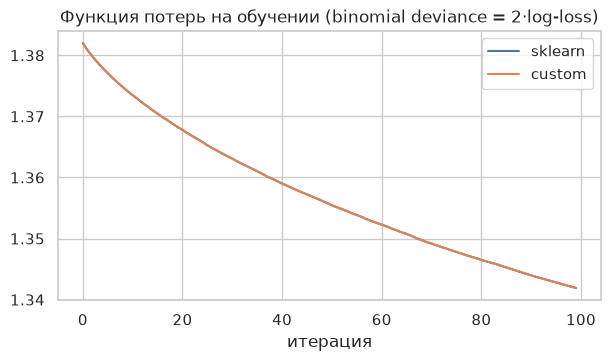

In [13]:
sk_proba = baseline_cls.predict_proba(X_cls_test)[:, 1]
my_proba = custom_cls.predict_proba(X_cls_test)[:, 1]
print(f"Макс. |разность вероятностей| (Dota 2): {np.max(np.abs(sk_proba - my_proba)):.2e}")
print(f"Макс. |разность предсказаний| (шахматы): "
      f"{np.max(np.abs(baseline_reg.predict(X_reg_test) - custom_reg.predict(X_reg_test))):.2e}")
ax = pd.DataFrame({
    "sklearn": baseline_cls.train_score_,
    "custom": np.array(custom_cls.train_loss_) * 2,
}).plot(figsize=(7, 3.5), title="Функция потерь на обучении (binomial deviance = 2·log-loss)")
ax.set_xlabel("итерация")
plt.show()

<!-- lab5_custom -->
**Вывод по собственной реализации.**
* Метрики собственного бустинга **совпадают** с `sklearn` до 4-го знака в обеих задачах (ROC-AUC 0.6118, R² 0.8697).
* На шахматах предсказания совпадают с машинной точностью (8.9e-16): деревья, значения в листьях и шаг обучения идентичны. На Dota 2 максимальная разница вероятностей 0.005 — следствие разного выбора среди равноценных разбиений в отдельных деревьях.
* Кривые функции потерь на обучении (binomial deviance) практически совпадают — алгоритм Фридмана с шагом Ньютона в листьях реализован так же, как в `sklearn`.
* На 116 дискретных признаках собственная реализация медленнее (28 с против 17 с): гистограмма строится сразу по всем признакам и всем объектам узла.

### 4.2. Собственная реализация + техники улучшенного бейзлайна

Используем собственный бустинг в конвейерах улучшенного бейзлайна с теми же признаками и гиперпараметрами. При `subsample < 1` подвыборки генерируются собственным генератором случайных чисел, поэтому полного совпадения с `sklearn` ожидать нельзя, а для непрерывных признаков драфта используется гистограммный поиск порогов (255 корзин).

In [14]:
best_cls = search_cls.best_params_
best_reg = search_reg.best_params_

def custom_params(best):
    return dict(n_estimators=best["model__n_estimators"], learning_rate=best["model__learning_rate"],
                max_depth=best["model__max_depth"], subsample=best["model__subsample"],
                random_state=RANDOM_STATE)

custom_improved_cls = Pipeline([
    ("features", DotaFeatures(meta="drop", heroes="none", synergy=True)),
    ("model", mllab.GradientBoostingClassifier(**custom_params(best_cls))),
], memory=memory)
custom_improved_reg = Pipeline([
    ("features", ChessFeatures()),
    ("model", mllab.GradientBoostingRegressor(**custom_params(best_reg))),
])

log.add("classification", "custom improved",
        evaluate(custom_improved_cls, X_cls_train, y_cls_train, X_cls_test, y_cls_test, "classification"))
log.add("regression", "custom improved",
        evaluate(custom_improved_reg, X_reg_train, y_reg_train, X_reg_test, y_reg_test, "regression"))
display(log.table("classification").loc[["sklearn improved", "custom improved"]],
        log.table("regression").loc[["sklearn improved", "custom improved"]])

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn improved,0.6385,0.5969,0.6353,33.7252,0.0664
custom improved,0.6387,0.5963,0.6348,4.7719,0.1332


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn improved,0.9840,0.0631,0.0127,1.7218,0.0152
custom improved,0.9834,0.0645,0.0137,4.2821,0.0566


<!-- lab5_custom_improved -->
**Вывод.** С техниками улучшенного бейзлайна собственный бустинг даёт ROC-AUC 0.6387 (у `sklearn` 0.6385) и R² 0.983 (у `sklearn` 0.984); различия — следствие разных случайных подвыборок (`subsample = 0.8`) и квантования порогов непрерывных признаков драфта. Прирост относительно собственного бейзлайна такой же, как у `sklearn`: +0.027 ROC-AUC и +0.114 R². На непрерывных признаках гистограммный подход даёт выигрыш в скорости в 7 раз (4.8 с против 34 с), а на глубоких деревьях для шахмат собственная реализация медленнее (4.3 с против 1.7 с) — сказывается обработка узлов в цикле Python.

## 5. Итоги лабораторной работы

Сводная таблица всех вариантов; результаты сохраняются в `results/lab5.json`. Сравнение всех алгоритмов ЛР №1–5 — в ноутбуке `summary.ipynb`.

,roc_auc,accuracy,f1,fit_time,predict_time
variant,,,,,
sklearn baseline,0.6118,0.5814,0.6559,16.6416,0.0365
sklearn improved,0.6385,0.5969,0.6353,33.7252,0.0664
custom,0.6118,0.5814,0.6559,28.4513,0.0763
custom improved,0.6387,0.5963,0.6348,4.7719,0.1332


,r2,rmse,mae,fit_time,predict_time
variant,,,,,
sklearn baseline,0.8697,0.1803,0.1171,0.2487,0.0041
sklearn improved,0.9840,0.0631,0.0127,1.7218,0.0152
custom,0.8697,0.1803,0.1171,0.2105,0.0090
custom improved,0.9834,0.0645,0.0137,4.2821,0.0566


Сохранено: results/lab5.json


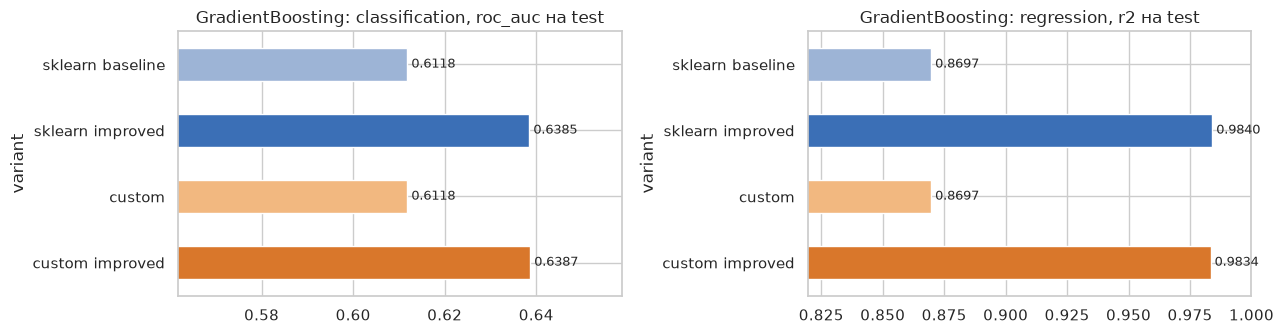

In [15]:
display(log.table("classification"), log.table("regression"))
log.plot()
print("Сохранено:", log.save().relative_to(ROOT))

<!-- lab5_summary -->
**Выводы по ЛР №5.**
1. Градиентный бустинг с параметрами по умолчанию на Dota 2 уступает логистической регрессии, а на шахматах недообучен (R² 0.87) — параметры по умолчанию для бустинга далеки от оптимальных и сильно зависят от задачи.
2. Для Dota 2 оптимальны признаки драфта, малый темп обучения (0.03) и очень неглубокие деревья (глубина 2): сигнал почти аддитивный, и бустинг быстро переобучается. Итог: ROC-AUC 0.612 → 0.639.
3. Для шахмат, наоборот, нужны глубокие деревья (глубина 9), выражающие сложные логические правила: R² 0.870 → 0.984.
4. Собственная реализация (антиградиент + регрессионные деревья + шаг Ньютона в листьях) совпадает с `sklearn` вплоть до машинной точности на дискретных признаках.

Итоговое сравнение всех алгоритмов — в ноутбуке `summary.ipynb`.